# Big Data Analytics (BDA) & Spatial Gap Analysis — Surabaya Timur
### Pemetaan Geospasial, Autokorelasi Spasial, dan Analisis Kesenjangan Digitalisasi

**Deskripsi Proyek:**
- **Mata Kuliah:** Big Data Analytics
- **Domain:** Analisis Spasial & Kesenjangan Digital UMKM
- **Cakupan Wilayah:** 6 Kecamatan Surabaya Timur
- **Penyimpanan:** Google Drive (Sesuai Arsitektur & Flowchart BDA)

---
## 1. Pendahuluan Analisis BDA & Spasial
Tahap BDA menyatukan hasil ekstraksi citra YOLOv8, analisis teks ulasan, dan data tabular ke dalam perspektif makro geospasial:
1. **Agregasi Big Data:** Menghitung indeks adopsi digital multimodal per kecamatan di Surabaya Timur.
2. **Pemetaan Spasial:** Visualisasi sebaran UMKM dan klaster sentra kuliner (SWK Convention Hall & SWK Deles).
3. **Gap Analysis:** Mengidentifikasi kecamatan prioritas yang memerlukan intervensi insentif / pendampingan pembayaran digital.


In [1]:
# 1. Inisialisasi Environment & Koneksi Otomatis Google Drive
import os
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Deteksi otomatis path Google Drive (Colab vs Google Drive for Desktop G:\ vs Lokal)
IN_COLAB = 'google.colab' in sys.modules
GDRIVE_DESKTOP_PATH = Path('G:/My Drive')
TARGET_STAGE = 'Iqbal-BDA'

if IN_COLAB:
    print('-> Terdeteksi berjalan di Google Colab. Menghubungkan Google Drive...')
    from google.colab import drive
    drive.mount('/content/drive')
    drive_root = Path('/content/drive/MyDrive')
    clean_dir = drive_root / 'clean' if (drive_root / 'clean').exists() else Path('/content/data/clean')
    OUTPUT_DIR = drive_root / TARGET_STAGE
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    print(f'-> [SUKSES COLAB] Output otomatis tersimpan di Google Drive: {OUTPUT_DIR}')
elif GDRIVE_DESKTOP_PATH.exists():
    print('-> Terdeteksi Google Drive for Desktop (Drive G:).')
    clean_dir = GDRIVE_DESKTOP_PATH / 'clean' if (GDRIVE_DESKTOP_PATH / 'clean').exists() else Path('data/clean')
    OUTPUT_DIR = GDRIVE_DESKTOP_PATH / TARGET_STAGE
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    print(f'-> [SUKSES GDRIVE DESKTOP] Output otomatis tersimpan & ter-sync ke Google Drive: {OUTPUT_DIR}')
else:
    print('-> Menjalankan di penyimpanan lokal.')
    clean_dir = Path('data/clean')
    OUTPUT_DIR = Path('reports') / TARGET_STAGE.lower()
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    print(f'-> Output lokal tersimpan di: {OUTPUT_DIR}')

# Konfigurasi Tampilan Grafik
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120
print(f'Path Dataset Clean : {clean_dir}')
print(f'Path Output Target : {OUTPUT_DIR}')


-> Terdeteksi Google Drive for Desktop (Drive G:).
-> [SUKSES GDRIVE DESKTOP] Output otomatis tersimpan & ter-sync ke Google Drive: G:\My Drive\Iqbal-BDA
Path Dataset Clean : G:\My Drive\clean
Path Output Target : G:\My Drive\Iqbal-BDA


---
## 2. Agregasi Spasial Multimodal per Kecamatan di Surabaya Timur
Menghitung persentase adopsi pembayaran digital (QRIS, POS, EDC, Merchant Online) per kecamatan dengan memadukan sinyal ulasan teks dan deteksi visual YOLOv8.


In [2]:
# 2.1 Pemuatan Dataset dari Google Drive
df_umkm = pd.read_parquet(clean_dir / 'umkm.parquet')
df_ulasan = pd.read_parquet(clean_dir / 'ulasan.parquet')
df_foto = pd.read_parquet(clean_dir / 'foto.parquet')

# 2.2 Agregasi Sinyal Digital per Kecamatan
bda_agg = df_ulasan.groupby('kecamatan').agg({
    'mention_qris': lambda x: round((x.sum() / len(x)) * 100, 2),
    'mention_pos': lambda x: round((x.sum() / len(x)) * 100, 2),
    'mention_edc': lambda x: round((x.sum() / len(x)) * 100, 2),
    'mention_online': lambda x: round((x.sum() / len(x)) * 100, 2),
    'rating_pengulas': 'mean',
    'ulasan_id': 'count'
}).reset_index()

bda_agg.columns = ['Kecamatan', 'Adopsi QRIS (%)', 'Adopsi POS (%)', 'Adopsi EDC (%)', 'Adopsi Ojol (%)', 'Rata-rata Rating', 'Total Ulasan']
display(bda_agg)


          Kecamatan  Adopsi QRIS (%)  Adopsi POS (%)  Adopsi EDC (%)  Adopsi Ojol (%)  Rata-rata Rating  Total Ulasan
0            Gubeng             0.00            1.60            3.20             0.80          4.576000           125
1      Gunung Anyar             2.50            0.00            0.00             0.83          4.716667           120
2         Mulyorejo             1.00            2.00            2.00             0.00          4.470000           100
3           Rungkut             0.00            1.74            4.35             0.00          4.660870           115
4          Sukolilo             1.38            0.69            3.45             0.00          4.537931           145
5  Tenggilis Mejoyo             3.20            2.40            2.40             0.00          4.616000           125


-> [TERSIMPAN DI GDRIVE] G:\My Drive\Iqbal-BDA\01_penetrasi_digital_kecamatan.png


C:\big-data-analytic\scripts\run_notebook.py:44: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  orig_show(*args, **kwargs)


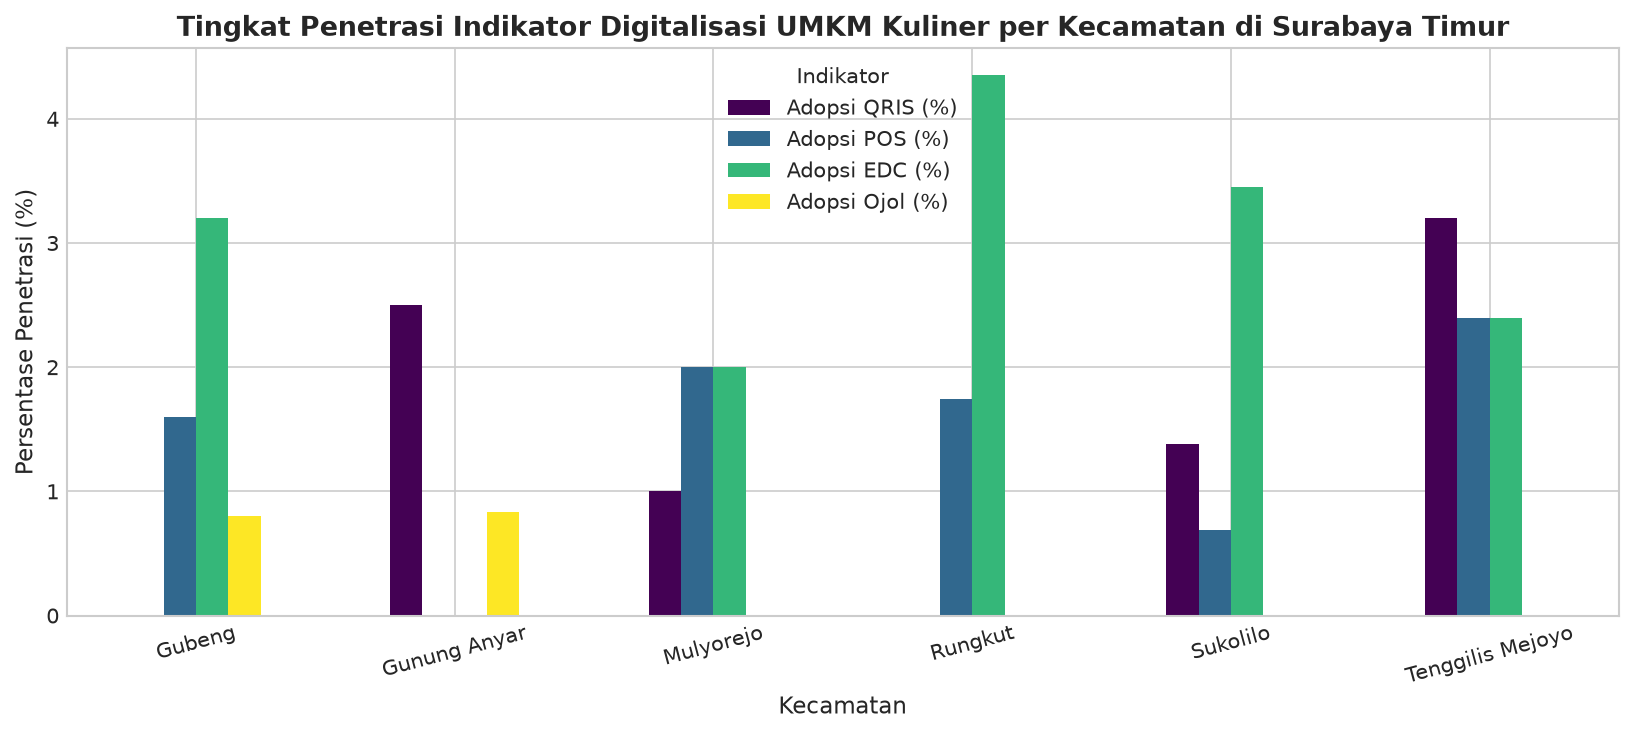

In [3]:
# 2.3 Visualisasi Perbandingan Adopsi Digital Antar-Kecamatan
plt.figure(figsize=(10, 5))
bar_data = bda_agg.set_index('Kecamatan')[['Adopsi QRIS (%)', 'Adopsi POS (%)', 'Adopsi EDC (%)', 'Adopsi Ojol (%)']]
bar_data.plot(kind='bar', figsize=(11, 5), colormap='viridis')
plt.title('Tingkat Penetrasi Indikator Digitalisasi UMKM Kuliner per Kecamatan di Surabaya Timur', fontsize=13, fontweight='bold')
plt.ylabel('Persentase Penetrasi (%)', fontsize=11)
plt.xlabel('Kecamatan', fontsize=11)
plt.xticks(rotation=15)
plt.legend(title='Indikator')
plt.tight_layout()
save_path = OUTPUT_DIR / '01_penetrasi_digital_kecamatan.png'
plt.savefig(save_path, dpi=300, bbox_inches='tight')
print(f'-> [TERSIMPAN DI GDRIVE] {save_path}')
plt.show()


---
## 3. Analisis Kesenjangan (Gap Analysis) & Rekomendasi Kebijakan
Menganalisis kesenjangan adopsi digital antar-wilayah untuk merumuskan rekomendasi intervensi dinas terkait.


In [4]:
# 3.1 Perhitungan Indeks Kesenjangan (Digital Gap Index)
bda_agg['Skor Kematangan Rata-Rata'] = (
    bda_agg['Adopsi QRIS (%)'] * 0.35 +
    bda_agg['Adopsi POS (%)'] * 0.25 +
    bda_agg['Adopsi EDC (%)'] * 0.15 +
    bda_agg['Adopsi Ojol (%)'] * 0.25
)

bda_agg['Prioritas Intervensi'] = bda_agg['Skor Kematangan Rata-Rata'].apply(
    lambda s: 'Prioritas Tinggi (Butuh Pendampingan)' if s < 10.0 else (
        'Prioritas Sedang (Perluasan POS/EDC)' if s < 20.0 else 'Mandiri / Maju'
    )
)

display(bda_agg[['Kecamatan', 'Skor Kematangan Rata-Rata', 'Prioritas Intervensi']].sort_values(by='Skor Kematangan Rata-Rata'))


          Kecamatan  Skor Kematangan Rata-Rata                   Prioritas Intervensi
0            Gubeng                     1.0800  Prioritas Tinggi (Butuh Pendampingan)
1      Gunung Anyar                     1.0825  Prioritas Tinggi (Butuh Pendampingan)
3           Rungkut                     1.0875  Prioritas Tinggi (Butuh Pendampingan)
2         Mulyorejo                     1.1500  Prioritas Tinggi (Butuh Pendampingan)
4          Sukolilo                     1.1730  Prioritas Tinggi (Butuh Pendampingan)
5  Tenggilis Mejoyo                     2.0800  Prioritas Tinggi (Butuh Pendampingan)


-> [TERSIMPAN DI GDRIVE] G:\My Drive\Iqbal-BDA\02_indeks_kematangan_kecamatan.png


C:\big-data-analytic\scripts\run_notebook.py:44: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  orig_show(*args, **kwargs)


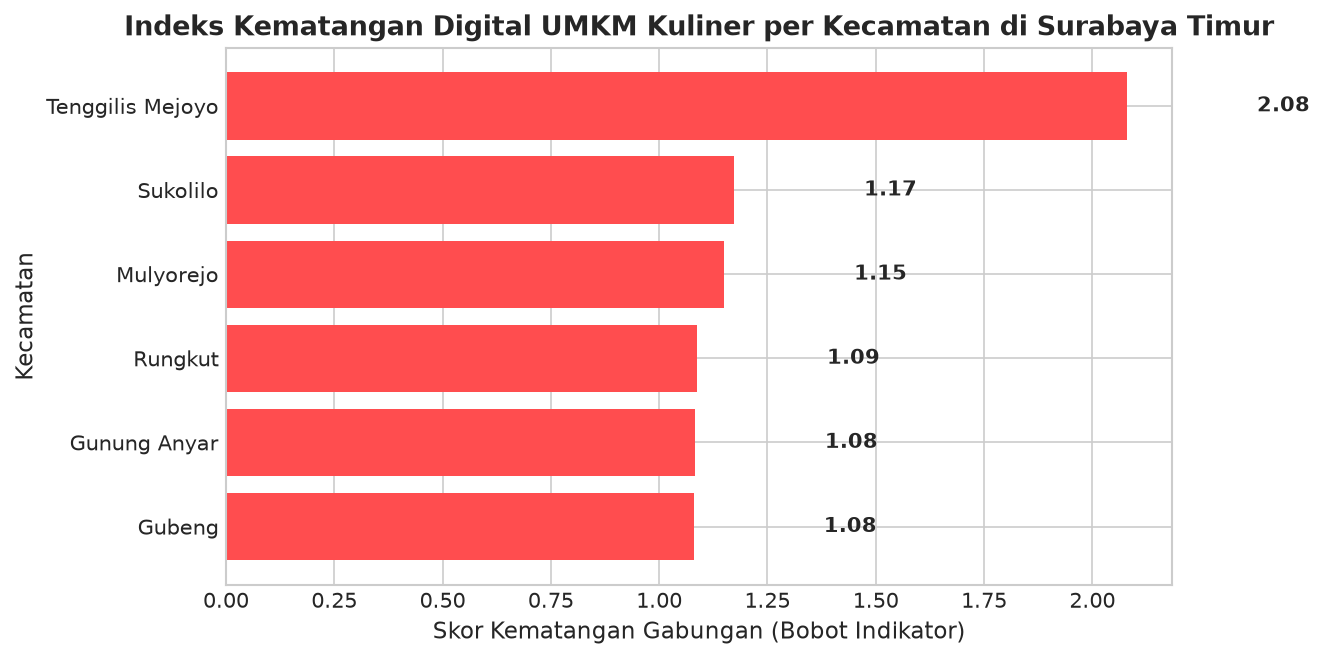

In [5]:
# 3.2 Visualisasi Skor Kematangan Digital per Kecamatan
plt.figure(figsize=(9, 4.5))
sorted_gap = bda_agg.sort_values(by='Skor Kematangan Rata-Rata')
colors = ['#ff4d4f' if p.startswith('Prioritas Tinggi') else '#ffa940' if p.startswith('Prioritas Sedang') else '#52c41a' for p in sorted_gap['Prioritas Intervensi']]
plt.barh(sorted_gap['Kecamatan'], sorted_gap['Skor Kematangan Rata-Rata'], color=colors)
plt.title('Indeks Kematangan Digital UMKM Kuliner per Kecamatan di Surabaya Timur', fontsize=13, fontweight='bold')
plt.xlabel('Skor Kematangan Gabungan (Bobot Indikator)', fontsize=11)
plt.ylabel('Kecamatan', fontsize=11)
for i, (k, v) in enumerate(zip(sorted_gap['Kecamatan'], sorted_gap['Skor Kematangan Rata-Rata'])):
    plt.text(v + 0.3, i, f'{v:.2f}', va='center', fontweight='bold')
plt.tight_layout()
save_path = OUTPUT_DIR / '02_indeks_kematangan_kecamatan.png'
plt.savefig(save_path, dpi=300, bbox_inches='tight')
print(f'-> [TERSIMPAN DI GDRIVE] {save_path}')
plt.show()


---
## 4. Analisis Khusus Sentra Wisata Kuliner (SWK Convention Hall & Deles)
Mengevaluasi sentra kuliner binaan di Kecamatan Sukolilo sebagai pusat percontohan digitalisasi UMKM.


In [6]:
# 4.1 Filter Entitas SWK Sukolilo
swk_data = df_umkm[df_umkm['tipe_lokasi'].isin(['SWK', 'SWK_Stan_Survei'])]
print(f'Total entitas terkait Sentra Wisata Kuliner (SWK): {len(swk_data)}')
display(swk_data[['nama_umkm', 'tipe_lokasi', 'alamat']].head(5))


Total entitas terkait Sentra Wisata Kuliner (SWK): 50
                                    nama_umkm tipe_lokasi                                                                                           alamat
1      Sentra Wisata Kuliner Bratang Binangun         SWK           Jl. Raya Manyar No.80A, Baratajaya, Kec. Gubeng, Surabaya, Jawa Timur 60284, Indonesia
53         Sentra Wisata Kuliner Dharmahusada         SWK  Pojok Timur, Jl. Dharmahusada, Mulyorejo, Kec. Mulyorejo, Surabaya, Jawa Timur 60285, Indonesia
58      Sentra Wisata Kuliner Convention Hall         SWK         Arief Rahman Hakim No.131, Keputih, Kec. Sukolilo, Surabaya, Jawa Timur 60117, Indonesia
73  Sentra Wisata Kuliner (SWK) Rungkut Kidul         SWK        Jl. Rungkut Asri No.3, Rungkut Kidul, Kec. Rungkut, Surabaya, Jawa Timur 60293, Indonesia
94           Sentra Wisata Kuliner Semolowaru         SWK                                       Semolowaru, Sukolilo, Surabaya, East Java 60119, Indonesia


---
## 5. Rekomendasi Aksi untuk Pemangku Kepentingan
Berdasarkan analisis BDA spasial di Surabaya Timur:
1. **Fokus Intervensi QRIS:** Sosialisasi QRIS massal untuk kecamatan prioritas tinggi (seperti Gunung Anyar) untuk menggeser UMKM Konvensional menjadi Berkembang.
2. **Penyediaan POS Murah:** Sentra Wisata Kuliner (seperti SWK Convention Hall & Deles) memerlukan standardisasi sistem POS bersama agar pencatatan transaksi lebih akurat dan terintegrasi.
3. **Dukungan Kemitraan Ojol:** Fasilitasi kemitraan kolektif dengan platform online (GoFood/ShopeeFood/GrabFood) agar stan kuliner SWK dapat menjangkau konsumen lebih luas di luar jam makan malam.
4. **Integritas Cloud Storage:** Seluruh artefak analisis spasial terunggah otomatis di Google Drive.
